Iteration    0 | learning rate = 0.500 | radius = 5.00
Iteration  500 | learning rate = 0.423 | radius = 4.23
Iteration 1000 | learning rate = 0.358 | radius = 3.58
Iteration 1500 | learning rate = 0.303 | radius = 3.03
Iteration 2000 | learning rate = 0.257 | radius = 2.57
Iteration 2500 | learning rate = 0.217 | radius = 2.17
Training finished!
Image saved as som_result.png


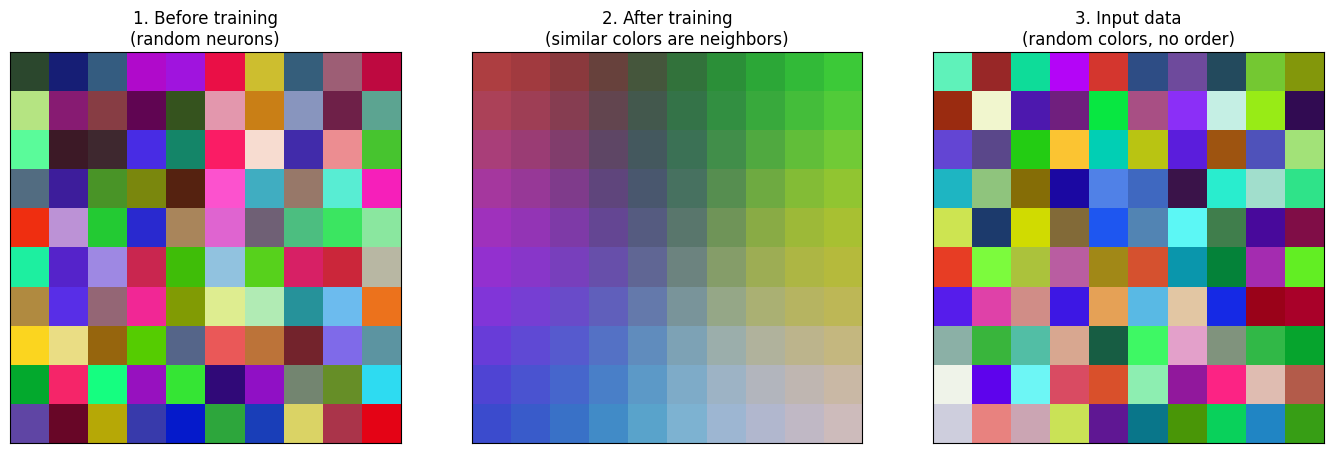

In [1]:

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

# ---------------- Settings ----------------
GRID_SIZE = 10
N_ITERATIONS = 3000
LEARNING_RATE_START = 0.5
RADIUS_START = GRID_SIZE / 2

# ---------------- Data ----------------
data = np.random.rand(200, 3)

# Step 1: Initialize
weights = np.random.rand(GRID_SIZE, GRID_SIZE, 3)
weights_before = weights.copy()

# Row and column number of every neuron (used for neighborhood distance)
rows, cols = np.indices((GRID_SIZE, GRID_SIZE))

# ---------------- Training loop ----------------
for t in range(N_ITERATIONS):

    # Learning rate and radius shrink over time
    decay = np.exp(-t / N_ITERATIONS)
    learning_rate = LEARNING_RATE_START * decay
    radius = RADIUS_START * decay

    # Step 2: Pick one random sample
    x = data[np.random.randint(len(data))]

    # Step 3: Find the winner (BMU) = neuron with smallest distance to x
    distances = np.sqrt(((weights - x) ** 2).sum(axis=2))
    bmu_row, bmu_col = np.unravel_index(np.argmin(distances), distances.shape)

    # Step 4: Neighborhood - neurons near the winner get a bigger effect (h)
    grid_dist_sq = (rows - bmu_row) ** 2 + (cols - bmu_col) ** 2
    h = np.exp(-grid_dist_sq / (2 * radius ** 2))

    # Step 5: Update weights: w_new = w_old + alpha * h * (x - w_old)
    weights += learning_rate * h[:, :, np.newaxis] * (x - weights)

    # Step 6: Repeat (the for loop does this)

    if t % 500 == 0:
        print(f"Iteration {t:4d} | learning rate = {learning_rate:.3f} | radius = {radius:.2f}")

print("Training finished!")

# ---------------- Show results ----------------
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

axes[0].imshow(weights_before)
axes[0].set_title("1. Before training\n(random neurons)")

axes[1].imshow(weights)
axes[1].set_title("2. After training\n(similar colors are neighbors)")

# Show the input data as a simple strip of colors for reference
axes[2].imshow(data[:100].reshape(10, 10, 3))
axes[2].set_title("3. Input data\n(random colors, no order)")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])

plt.tight_layout()
plt.savefig("som_result.png", dpi=150)
print("Image saved as som_result.png")
plt.show()
